# NN_L13_load_mape

**Mean absolute percentage error of day-ahead forecasts of Romanian hourly load in the test year: same hour last week, TimesFM 2.5 and Chronos-2, both zero-shot.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_load_mape/NN_L13_load_mape.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

MAPE week (%) = 7.15   [load.week.mape]
MAPE timesfm (%) = 4.47   [load.timesfm.mape]
MAPE chronos2 (%) = 3.8   [load.chronos2.mape]


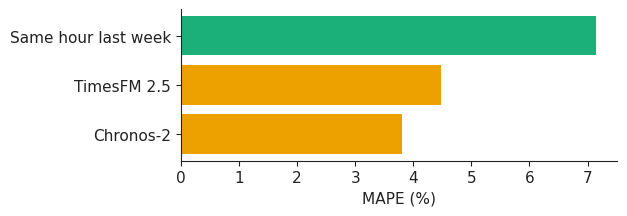

In [3]:
RES = REPO + 'lectures/L13/results/'
A = pd.read_csv(RES + 'load_actual.csv', index_col=0)
LF = pd.read_csv(RES + 'load_forecasts.csv', index_col=[0, 1])
mape = {}
for m in ['week', 'timesfm', 'chronos2']:
    P = LF.loc[m].values
    mape[m] = round(float(100 * np.abs((P - A.values) / A.values).mean()), 2)
    show(f'load.{m}.mape', f'MAPE {m} (%)', mape[m])
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.barh(range(3), list(mape.values()), color=[PAL['benchmark'], PAL['alt'], PAL['alt']])
ax.set_yticks(range(3))
ax.set_yticklabels(['Same hour last week', 'TimesFM 2.5', 'Chronos-2'])
ax.invert_yaxis()
ax.set_xlabel('MAPE (%)')
fig.tight_layout()
fig.savefig('load_mape.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()